# 1. Thu thập và đọc dữ liệu


In [1]:
import pandas as pd
from pyspark.sql import SparkSession
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
import seaborn as sns
import matplotlib.pyplot as plt

spark = SparkSession.builder.appName("Random_Forest").getOrCreate()
df = spark.read.parquet("/Users/mac/Downloads/Graph_Analytics_For_Discovering_Emerging_Influential_Papers/data/processed/citation_ml_dataset.parquet")


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/06 16:48:34 WARN Utils: Your hostname, MacBook-Pro-5.local, resolves to a loopback address: 127.0.0.1; using 192.168.1.49 instead (on interface en0)
26/11/06 16:48:34 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/11/06 16:48:35 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/06 16:48:35 WARN 

# 2. Thống kê dữ liệu


In [2]:
print("Số lượng dòng:", df.count())
print("Số lượng cột:", len(df.columns))
df.printSchema()


Số lượng dòng: 694450
Số lượng cột: 13
root
 |-- paper_id: long (nullable = true)
 |-- pub_year: long (nullable = true)
 |-- past_in_degree: long (nullable = true)
 |-- num_authors: long (nullable = true)
 |-- num_topics: long (nullable = true)
 |-- pagerank_score: double (nullable = true)
 |-- paper_age: long (nullable = true)
 |-- citation_velocity: double (nullable = true)
 |-- paper_feat_128d: vector (nullable = true)
 |-- delta_c: long (nullable = true)
 |-- ogb_split: string (nullable = true)
 |-- label: double (nullable = true)
 |-- temporal_split: string (nullable = true)



# 3. Trực quan hóa dữ liệu


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/var/folders/bj/4zbr51sj4fsbvtllcchl3wzc0000gn/T/ipykernel_22494/3789449976.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="label", y="count", data=label_counts, palette=["blue", "red"])


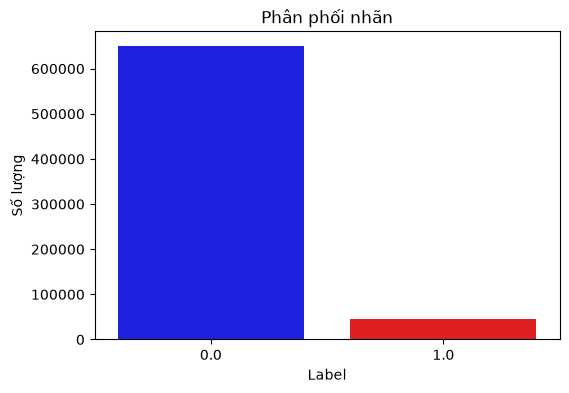

   label   count
0    0.0  649837
1    1.0   44613


In [3]:
label_counts = df.groupBy("label").count().toPandas()
plt.figure(figsize=(6, 4))
sns.barplot(x="label", y="count", data=label_counts, palette=["blue", "red"])
plt.title("Phân phối nhãn")
plt.xlabel("Label")
plt.ylabel("Số lượng")
plt.show()
print(label_counts)


# 4. Tiền xử lý dữ liệu và chia tập dữ liệu


In [4]:
features = ["citation_velocity", "pagerank_score", "paper_age"]
target = "label"

assembler = VectorAssembler(inputCols=features, outputCol="raw_features")
assembled_df = assembler.transform(df)

train_data = assembled_df.filter(assembled_df["temporal_split"] == "train")
val_data = assembled_df.filter(assembled_df["temporal_split"] == "valid")
test_data = assembled_df.filter(assembled_df["temporal_split"] == "test")

print("Train:", train_data.count())
print("Validation:", val_data.count())
print("Test:", test_data.count())

scaler = StandardScaler(inputCol="raw_features", outputCol="scaled_features", withMean=True, withStd=True)
scaler_model = scaler.fit(train_data)

train_scaled = scaler_model.transform(train_data)
val_scaled = scaler_model.transform(val_data)
test_scaled = scaler_model.transform(test_data)


Train: 559373
Validation: 70198
Test: 64879


In [5]:
from pyspark.sql.functions import col, when

# Đếm số lượng từng lớp
counts = {
    r["label"]: r["count"]
    for r in train_scaled.groupBy("label").count().collect()
}

total = sum(counts.values())

# Tính trọng số cho từng lớp
weight_0 = total / (2 * counts[0.0])
weight_1 = total / (2 * counts[1.0])

# Gán trọng số
train_weighted = train_scaled.withColumn(
    "class_weight",
    when(col("label") == 0.0, weight_0)
    .otherwise(weight_1)
)

train_weighted.groupBy("label").agg(
    {"class_weight": "avg"}
).show()

+-----+------------------+
|label| avg(class_weight)|
+-----+------------------+
|  0.0|0.5273511815538862|
|  1.0| 9.640372949124767|
+-----+------------------+



# 5. Model Training (Huấn luyện mô hình)


In [6]:
rf = RandomForestClassifier(featuresCol="scaled_features", labelCol=target, numTrees=30, maxDepth=5, seed=42,     weightCol="class_weight")
rf_model = rf.fit(train_weighted)

print("Feature Importances:", rf_model.featureImportances)


26/11/06 16:48:41 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


Feature Importances: (3,[0,1,2],[0.8765348598496351,0.10529587881734322,0.01816926133302167])


# 6. Model Validation (Kiểm định trên tập Validation)


In [7]:
val_predictions = rf_model.transform(val_scaled)

pr_evaluator = BinaryClassificationEvaluator(labelCol=target, rawPredictionCol="probability", metricName="areaUnderPR")
roc_evaluator = BinaryClassificationEvaluator(labelCol=target, rawPredictionCol="probability", metricName="areaUnderROC")
f1_evaluator = MulticlassClassificationEvaluator(labelCol=target, predictionCol="prediction", metricName="f1")

print("Validation PR-AUC:", pr_evaluator.evaluate(val_predictions))
print("Validation ROC-AUC:", roc_evaluator.evaluate(val_predictions))
print("Validation F1-Score:", f1_evaluator.evaluate(val_predictions))


Validation PR-AUC: 0.5908794719069013
Validation ROC-AUC: 0.9010367248007075
Validation F1-Score: 0.8882044212401652


# 7. Model Testing (Đánh giá trên tập Test)


In [8]:
test_predictions = rf_model.transform(test_scaled)

print("Test PR-AUC:", pr_evaluator.evaluate(test_predictions))
print("Test ROC-AUC:", roc_evaluator.evaluate(test_predictions))
print("Test F1-Score:", f1_evaluator.evaluate(test_predictions))


Test PR-AUC: 0.5052028842286104
Test ROC-AUC: 0.7860864955409488
Test F1-Score: 0.8560234715436048


In [9]:
test_predictions.select("paper_id", "label", "prediction", "probability").show(10, truncate=False)


+--------+-----+----------+----------------------------------------+
|paper_id|label|prediction|probability                             |
+--------+-----+----------+----------------------------------------+
|3383    |0.0  |0.0       |[0.9436072214183016,0.05639277858169845]|
|9588    |0.0  |0.0       |[0.9436072214183016,0.05639277858169845]|
|10024   |0.0  |0.0       |[0.882359341871366,0.11764065812863397] |
|87870   |1.0  |1.0       |[0.07714713508418444,0.9228528649158156]|
|455608  |1.0  |1.0       |[0.08399579892261558,0.9160042010773845]|
|456269  |0.0  |0.0       |[0.9436072214183016,0.05639277858169845]|
|466691  |0.0  |1.0       |[0.29626601538037417,0.7037339846196259]|
|472841  |0.0  |0.0       |[0.8649013508168806,0.13509864918311934]|
|478300  |0.0  |0.0       |[0.9436072214183016,0.05639277858169845]|
|493006  |0.0  |1.0       |[0.2632835517116392,0.7367164482883608] |
+--------+-----+----------+----------------------------------------+
only showing top 10 rows


In [10]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

# 1. Accuracy
acc_eval = MulticlassClassificationEvaluator(labelCol=target, predictionCol="prediction", metricName="accuracy")

# 2. Precision, Recall, F1 riêng cho nhãn 1 (metricLabel=1.0)
prec1_eval = MulticlassClassificationEvaluator(labelCol=target, predictionCol="prediction", metricName="precisionByLabel", metricLabel=1.0)
rec1_eval = MulticlassClassificationEvaluator(labelCol=target, predictionCol="prediction", metricName="recallByLabel", metricLabel=1.0)
f1_1_eval = MulticlassClassificationEvaluator(labelCol=target, predictionCol="prediction", metricName="f1", metricLabel=1.0)

# 3. Precision, Recall, F1 riêng cho nhãn 1 (metricLabel=0)
prec0_eval = MulticlassClassificationEvaluator(labelCol=target, predictionCol="prediction", metricName="precisionByLabel", metricLabel=0.0)
rec0_eval = MulticlassClassificationEvaluator(labelCol=target, predictionCol="prediction", metricName="recallByLabel", metricLabel=0.0)
f1_0_eval = MulticlassClassificationEvaluator(labelCol=target, predictionCol="prediction", metricName="f1", metricLabel=0.0)

print(f"Test Accuracy:          {acc_eval.evaluate(test_predictions):.4f}")
print(f"Test Precision (Lớp 1): {prec1_eval.evaluate(test_predictions):.4f}")
print(f"Test Recall (Lớp 1):    {rec1_eval.evaluate(test_predictions):.4f}")
print(f"Test F1-Score (Lớp 1):  {f1_1_eval.evaluate(test_predictions):.4f}")


print(f"Test Accuracy:          {acc_eval.evaluate(test_predictions):.4f}")
print(f"Test Precision (Lớp 0): {prec0_eval.evaluate(test_predictions):.4f}")
print(f"Test Recall (Lớp 0):    {rec0_eval.evaluate(test_predictions):.4f}")
print(f"Test F1-Score (Lớp 0):  {f1_0_eval.evaluate(test_predictions):.4f}")

print(f"Test F1-Score (Weighted): {f1_evaluator.evaluate(test_predictions):.4f}")

Test Accuracy:          0.8494
Test Precision (Lớp 1): 0.4558
Test Recall (Lớp 1):    0.5661
Test F1-Score (Lớp 1):  0.8560
Test Accuracy:          0.8494
Test Precision (Lớp 0): 0.9292
Test Recall (Lớp 0):    0.8938
Test F1-Score (Lớp 0):  0.8560
Test F1-Score (Weighted): 0.8560


# 8. Trích xuất kết quả dự đoán


In [11]:
from sklearn.metrics import confusion_matrix, precision_recall_curve, roc_curve, auc

pred_pd = test_predictions.select("label", "prediction", "probability").toPandas()
y_true = pred_pd["label"].values
y_pred = pred_pd["prediction"].values
y_prob = pred_pd["probability"].apply(lambda v: float(v[1])).values


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


# 9. Biểu đồ 1: Confusion Matrix


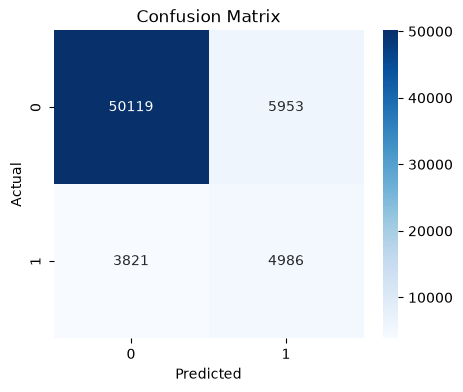

In [12]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["0", "1"], yticklabels=["0", "1"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


# 10. Biểu đồ 2: Precision-Recall Curve


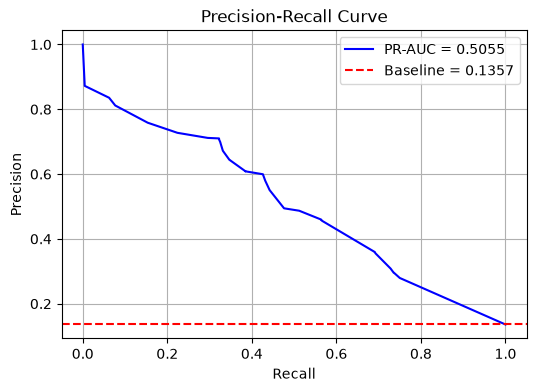

In [13]:
precision, recall, _ = precision_recall_curve(y_true, y_prob)
pr_auc_val = auc(recall, precision)

plt.figure(figsize=(6, 4))
plt.plot(recall, precision, color="blue", label=f"PR-AUC = {pr_auc_val:.4f}")
plt.axhline(y=y_true.mean(), color="red", linestyle="--", label=f"Baseline = {y_true.mean():.4f}")
plt.title("Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.grid(True)
plt.show()


# 11. Biểu đồ 3: ROC-AUC Curve


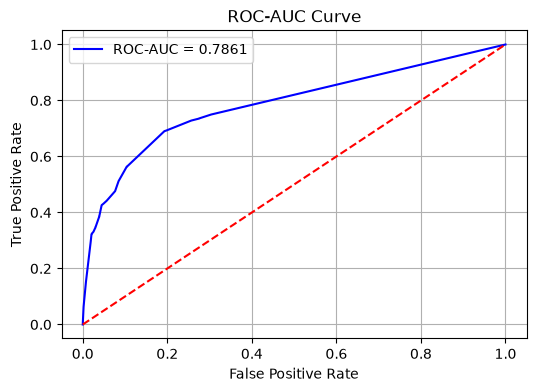

In [14]:
fpr, tpr, _ = roc_curve(y_true, y_prob)
roc_auc_val = auc(fpr, tpr)

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, color="blue", label=f"ROC-AUC = {roc_auc_val:.4f}")
plt.plot([0, 1], [0, 1], color="red", linestyle="--")
plt.title("ROC-AUC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()


In [15]:
spark.stop()